## 1. Import Library


In [2]:
import os
import sys
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Import helper untuk kompatibilitas Keras / TensorFlow
MobileNetV2 = tf.keras.applications.MobileNetV2
mobilenet_v2 = tf.keras.applications.mobilenet_v2
ImageDataGenerator = tf.keras.preprocessing.image.ImageDataGenerator

print('TensorFlow Version :', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU Terdeteksi     :', len(gpus), [gpu.name for gpu in gpus])
print('Semua library berhasil di-import.')


TensorFlow Version : 2.20.0
GPU Terdeteksi     : 2 ['/physical_device:GPU:0', '/physical_device:GPU:1']
Semua library berhasil di-import.


## 2. Setup Direktori & Parameter Training


In [3]:
# Deteksi otomatis path dataset di Kaggle
KAGGLE_INPUT = '/kaggle/input'
DATASET_BASE = None

for root, dirs, files in os.walk(KAGGLE_INPUT):
    if 'train' in dirs and 'val' in dirs and 'test' in dirs:
        DATASET_BASE = root
        break

if DATASET_BASE is None:
    DATASET_BASE = '/kaggle/input/datasets/vikaandini/rupiah-augmentasi/dataset'

TRAIN_DIR = os.path.join(DATASET_BASE, 'train')
VAL_DIR   = os.path.join(DATASET_BASE, 'val')
TEST_DIR  = os.path.join(DATASET_BASE, 'test')

# Direktori penyimpanan model di Kaggle
MODEL_DIR = '/kaggle/working/models'
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_SAVE_PATH    = os.path.join(MODEL_DIR, 'mobilenetv2_frozen.keras')
FINETUNE_SAVE_PATH = os.path.join(MODEL_DIR, 'mobilenetv2_finetuned.keras')
FINAL_MODEL_PATH   = os.path.join(MODEL_DIR, 'mobilenetv2_rupiah.keras')

# Parameter Training
IMG_SIZE        = (224, 224)
BATCH_SIZE      = 32
EPOCHS_FROZEN   = 15
EPOCHS_FINETUNE = 20
LR_FROZEN       = 1e-3
LR_FINETUNE     = 1e-4
NUM_CLASSES     = 7
CLASSES         = ['1000', '2000', '5000', '10000', '20000', '50000', '100000']
SEED            = 42

print('Path Dataset       :', DATASET_BASE)
print('Path Output Model  :', MODEL_DIR)
print('Kelas Nominal (7)  :', CLASSES)
print(f'Ukuran Gambar: {IMG_SIZE}, Batch Size: {BATCH_SIZE}, Epoch: {EPOCHS_FROZEN} (Tahap 1) + {EPOCHS_FINETUNE} (Tahap 2)')


Path Dataset       : /kaggle/input/datasets/vikaandini/rupiah-augmentasi/dataset
Path Output Model  : /kaggle/working/models
Kelas Nominal (7)  : ['1000', '2000', '5000', '10000', '20000', '50000', '100000']
Ukuran Gambar: (224, 224), Batch Size: 32, Epoch: 15 (Tahap 1) + 20 (Tahap 2)


## 3. Distribusi Data per Kelas


In [4]:
def count_images(split_dir):
    counts = {}
    for cls in CLASSES:
        cls_path = os.path.join(split_dir, cls)
        counts[cls] = len(list(pathlib.Path(cls_path).glob('*.jpg'))) if os.path.isdir(cls_path) else 0
    return counts

train_counts = count_images(TRAIN_DIR)
val_counts   = count_images(VAL_DIR)
test_counts  = count_images(TEST_DIR)

df_summary = pd.DataFrame({'Train': train_counts, 'Val': val_counts, 'Test': test_counts})
df_summary['Total'] = df_summary.sum(axis=1)
print('Distribusi jumlah gambar per split:')
display(df_summary)
print(f'Total sampel: Train={df_summary["Train"].sum()}, Val={df_summary["Val"].sum()}, Test={df_summary["Test"].sum()}')


Distribusi jumlah gambar per split:


,Train,Val,Test,Total
1000,130,15,21,166
2000,127,27,24,178
5000,111,26,30,167
10000,111,22,23,156
20000,135,29,25,189
50000,149,27,26,202
100000,131,30,30,191


Total sampel: Train=894, Val=176, Test=179


## 4. Data Preprocessing & Augmentasi


### 4.1. Definisi Augmentasi & Preprocessing


In [5]:
# Preprocessing V1: Rescale 1./255
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    brightness_range=[0.8, 1.2],
    horizontal_flip=False,
    vertical_flip=False,
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(rescale=1./255)
print('Pipeline ImageDataGenerator V1 (Rescale 1./255) berhasil dikonfigurasi.')


Pipeline ImageDataGenerator V1 (Rescale 1./255) berhasil dikonfigurasi.


### 4.2. Inisialisasi Data Generator (Train, Val, Test)


In [6]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASSES, shuffle=True, seed=SEED
)

val_generator = val_test_datagen.flow_from_directory(
    VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASSES, shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', classes=CLASSES, shuffle=False
)

print(f'Train generator : {train_generator.samples} gambar, {train_generator.num_classes} kelas, {len(train_generator)} batch') 
print(f'Val generator   : {val_generator.samples} gambar, {val_generator.num_classes} kelas, {len(val_generator)} batch')
print(f'Test generator  : {test_generator.samples} gambar, {test_generator.num_classes} kelas, {len(test_generator)} batch')


Found 894 images belonging to 7 classes.
Found 176 images belonging to 7 classes.
Found 179 images belonging to 7 classes.
Train generator : 894 gambar, 7 kelas, 28 batch
Val generator   : 176 gambar, 7 kelas, 6 batch
Test generator  : 179 gambar, 7 kelas, 6 batch


### 4.3. Visualisasi Sampel Gambar Augmentasi


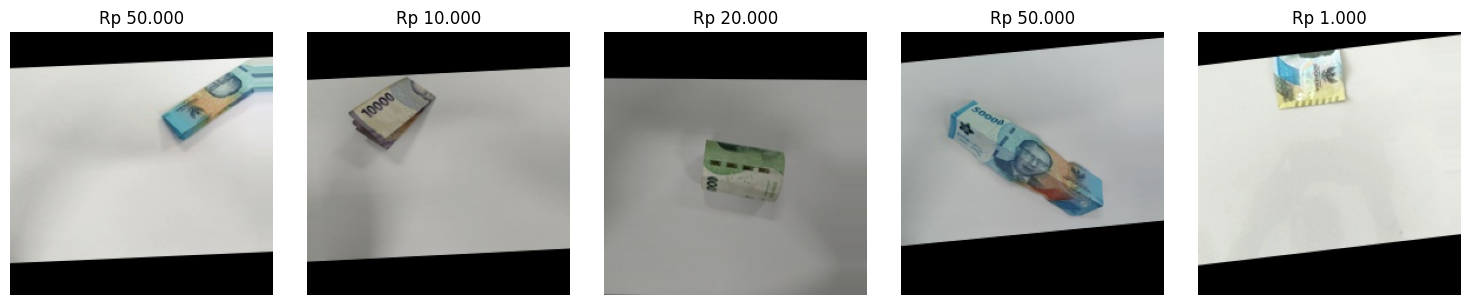

Sampel citra hasil augmentasi training berhasil ditampilkan.


In [7]:
batch_imgs, batch_lbls = next(train_generator)
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    axes[i].imshow(batch_imgs[i])
    nominal = CLASSES[np.argmax(batch_lbls[i])]
    axes[i].set_title(f'Rp {int(nominal):,}'.replace(',', '.'))
    axes[i].axis('off')
plt.tight_layout()
plt.show()
print('Sampel citra hasil augmentasi training berhasil ditampilkan.')


## 5. Arsitektur Model


### 5.1. Membangun Model Transfer Learning


In [8]:
def build_model_frozen(num_classes=7, img_size=(224, 224)):
    inputs = layers.Input(shape=(*img_size, 3), name='rupiah_input')
    base_model = MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_tensor=inputs
    )
    # Kunci seluruh layer backbone MobileNetV2 pada tahap 1
    base_model.trainable = False

    x = layers.GlobalAveragePooling2D(name='avg_pool')(base_model.output)
    x = layers.Dense(128, activation='relu', name='dense_head')(x)
    x = layers.Dropout(0.2, name='dropout_head')(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    model = models.Model(inputs, outputs, name='MobileNetV2_Rupiah_V1')
    model.compile(
        optimizer=optimizers.Adam(learning_rate=LR_FROZEN),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model, base_model

model, base_model = build_model_frozen(NUM_CLASSES, IMG_SIZE)
print('Model MobileNetV2 V1 (Baseline) berhasil dibangun.')
print(f'Total layer: {len(model.layers)}, Base model layer: {len(base_model.layers)}')


/tmp/ipykernel_46/452576049.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(
I0000 00:00:1793118872.728199      46 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793118872.732151      46 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model MobileNetV2 V1 (Baseline) berhasil dibangun.
Total layer: 158, Base model layer: 154


### 5.2. Ringkasan Arsitektur Model (Summary)


In [9]:
model.summary()


Model: "MobileNetV2_Rupiah_V1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rupiah_input        │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ rupiah_input[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,855 (9.24 MB)

 Trainable params: 164,871 (644.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Training Tahap 1: Classifier Head (Backbone Frozen)


In [10]:
callbacks_stage1 = [
    EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True, verbose=1),
    ModelCheckpoint(MODEL_SAVE_PATH, monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

print('Memulai Training Tahap 1: Classifier Head...')
history_stage1 = model.fit(
    train_generator,
    epochs=EPOCHS_FROZEN,
    validation_data=val_generator,
    callbacks=callbacks_stage1,
    verbose=1
)
print('Training Tahap 1 selesai.')
print('Checkpoint model Tahap 1 tersimpan di:', MODEL_SAVE_PATH)


Memulai Training Tahap 1: Classifier Head...
Epoch 1/15


2026-10-27 16:34:55.134444: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 16:34:55.272242: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793118897.726963     165 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


14/28 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.1944 - loss: 2.0710

2026-10-27 16:35:28.180141: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 16:35:28.317101: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2582 - loss: 1.9190

2026-10-27 16:36:08.162524: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 16:36:08.298982: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_accuracy improved from None to 0.65909, saving model to /kaggle/working/models/mobilenetv2_frozen.keras

Epoch 1: finished saving model to /kaggle/working/models/mobilenetv2_frozen.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 94s 3s/step - accuracy: 0.3669 - loss: 1.6590 - val_accuracy: 0.6591 - val_loss: 1.1103 - learning_rate: 0.0010
Epoch 2/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.6531 - loss: 1.0825
Epoch 2: val_accuracy improved from 0.65909 to 0.76705, saving model to /kaggle/working/models/mobilenetv2_frozen.keras

Epoch 2: finished saving model to /kaggle/working/models/mobilenetv2_frozen.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 12s 441ms/step - accuracy: 0.6935 - loss: 0.9460 - val_accuracy: 0.7670 - val_loss: 0.7198 - learning_rate: 0.0010
Epoch 3/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.7649 - loss: 0.7208
Epoch 3: val_accuracy improved from 0.76705 to 0.89205, saving model to /kaggle/working/models/mobilenetv2_frozen.keras

Epoch 3: finished savi

## 7. Training Tahap 2: Fine-Tuning


### 7.1. Unfreeze 30 Layer Backbone


In [11]:
# Unfreeze 30 layer teratas backbone MobileNetV2
UNFREEZE_COUNT = 30
base_model.trainable = True
for layer in base_model.layers[:-UNFREEZE_COUNT]:
    layer.trainable = False

model.compile(
    optimizer=optimizers.Adam(learning_rate=LR_FINETUNE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

trainable_params = sum(int(np.prod(v.shape)) for v in model.trainable_weights)
print(f'30 layer teratas dibuka untuk fine-tuning.')
print(f'Jumlah parameter trainable : {trainable_params:,}')
print(f'Learning rate fine-tuning  : {LR_FINETUNE}')


30 layer teratas dibuka untuk fine-tuning.
Jumlah parameter trainable : 1,691,271
Learning rate fine-tuning  : 0.0001


### 7.2. Eksekusi Training Fine-Tuning


In [12]:
callbacks_stage2 = [
    EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint(FINETUNE_SAVE_PATH, monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7, verbose=1)
]

print('Memulai Training Tahap 2: Fine-Tuning...')
history_stage2 = model.fit(
    train_generator,
    epochs=EPOCHS_FINETUNE,
    validation_data=val_generator,
    callbacks=callbacks_stage2,
    verbose=1
)
print('Training Tahap 2 selesai.')
print('Checkpoint model Tahap 2 tersimpan di:', FINETUNE_SAVE_PATH)


Memulai Training Tahap 2: Fine-Tuning...
Epoch 1/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 651ms/step - accuracy: 0.8337 - loss: 0.4696
Epoch 1: val_accuracy improved from None to 0.92614, saving model to /kaggle/working/models/mobilenetv2_finetuned.keras

Epoch 1: finished saving model to /kaggle/working/models/mobilenetv2_finetuned.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 41s 974ms/step - accuracy: 0.8669 - loss: 0.3907 - val_accuracy: 0.9261 - val_loss: 0.2018 - learning_rate: 1.0000e-04
Epoch 2/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 412ms/step - accuracy: 0.9239 - loss: 0.2019
Epoch 2: val_accuracy did not improve from 0.92614
28/28 ━━━━━━━━━━━━━━━━━━━━ 12s 428ms/step - accuracy: 0.9485 - loss: 0.1654 - val_accuracy: 0.8977 - val_loss: 0.2409 - learning_rate: 1.0000e-04
Epoch 3/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.9713 - loss: 0.1205
Epoch 3: val_accuracy did not improve from 0.92614

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
28/28 ━━━━━━━━━━━━━━━━━━

## 8. Visualisasi Kurva Training


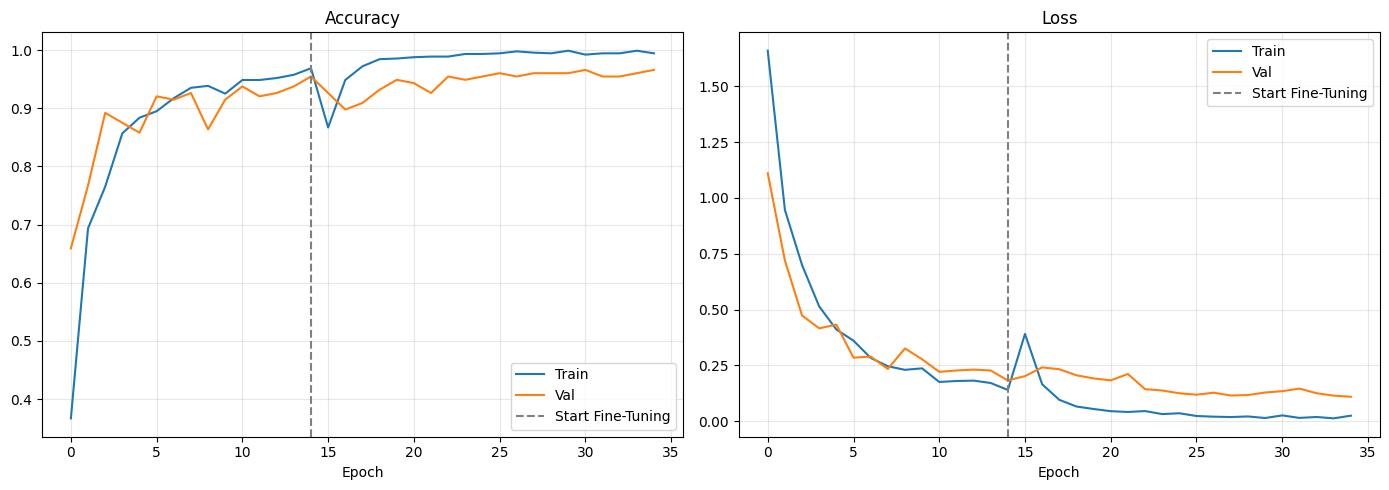

Kurva training (Tahap 1 & 2) berhasil ditampilkan dan disimpan ke: /kaggle/working/models/mobilenetv2_training_curves.png


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

acc = history_stage1.history['accuracy'] + history_stage2.history['accuracy']
val_acc = history_stage1.history['val_accuracy'] + history_stage2.history['val_accuracy']
loss = history_stage1.history['loss'] + history_stage2.history['loss']
val_loss = history_stage1.history['val_loss'] + history_stage2.history['val_loss']
split_epoch = len(history_stage1.history['accuracy'])

# Plot Akurasi
axes[0].plot(acc, label='Train')
axes[0].plot(val_acc, label='Val')
axes[0].axvline(split_epoch - 1, color='gray', linestyle='--', label='Start Fine-Tuning')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot Loss
axes[1].plot(loss, label='Train')
axes[1].plot(val_loss, label='Val')
axes[1].axvline(split_epoch - 1, color='gray', linestyle='--', label='Start Fine-Tuning')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
curve_path = os.path.join(MODEL_DIR, 'mobilenetv2_training_curves.png')
plt.savefig(curve_path, dpi=130)
plt.show()
print('Kurva training (Tahap 1 & 2) berhasil ditampilkan dan disimpan ke:', curve_path)


## 9. Evaluasi Model pada Data Test


### 9.1. Evaluasi Model Tahap 1 (Backbone Frozen)


In [14]:
# Memuat model checkpoint terbaik Tahap 1
model_frozen = tf.keras.models.load_model(MODEL_SAVE_PATH)
test_generator.reset()
probs_frozen = model_frozen.predict(test_generator, verbose=1)
pred_frozen  = np.argmax(probs_frozen, axis=1)
y_true       = test_generator.classes

acc_t1 = accuracy_score(y_true, pred_frozen)
p_t1, r_t1, f1_t1, _ = precision_recall_fscore_support(y_true, pred_frozen, average='macro')

print('=== Hasil Evaluasi Tahap 1 (Backbone Frozen) ===')
print(f'Test Accuracy  : {acc_t1*100:.2f}%')
print(f'Macro Precision: {p_t1:.4f}')
print(f'Macro Recall   : {r_t1:.4f}')
print(f'Macro F1-Score : {f1_t1:.4f}')


5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 929ms/step

2026-10-27 16:43:55.433413: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-27 16:43:55.570622: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


6/6 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step 
=== Hasil Evaluasi Tahap 1 (Backbone Frozen) ===
Test Accuracy  : 94.41%
Macro Precision: 0.9474
Macro Recall   : 0.9454
Macro F1-Score : 0.9446


### 9.2. Evaluasi Model Tahap 2 (Fine-Tuning)


In [15]:
# Memuat model checkpoint terbaik Tahap 2 (atau model saat ini)
model_ft = tf.keras.models.load_model(FINETUNE_SAVE_PATH) if os.path.exists(FINETUNE_SAVE_PATH) else model
test_generator.reset()
probs_ft = model_ft.predict(test_generator, verbose=1)
pred_ft  = np.argmax(probs_ft, axis=1)

acc_t2 = accuracy_score(y_true, pred_ft)
p_t2, r_t2, f1_t2, _ = precision_recall_fscore_support(y_true, pred_ft, average='macro')

print('=== Hasil Evaluasi Tahap 2 (Fine-Tuning) ===')
print(f'Test Accuracy  : {acc_t2*100:.2f}%')
print(f'Macro Precision: {p_t2:.4f}')
print(f'Macro Recall   : {r_t2:.4f}')
print(f'Macro F1-Score : {f1_t2:.4f}')


6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 857ms/step
=== Hasil Evaluasi Tahap 2 (Fine-Tuning) ===
Test Accuracy  : 95.53%
Macro Precision: 0.9584
Macro Recall   : 0.9543
Macro F1-Score : 0.9547


### 9.3. Tabel Perbandingan Evaluasi (Tahap 1 vs Tahap 2)


In [16]:
df_metrics = pd.DataFrame({
    'Tahapan': ['Tahap 1 (Backbone Frozen)', 'Tahap 2 (Fine-Tuning)', 'Peningkatan'],
    'Test Accuracy': [f'{acc_t1*100:.2f}%', f'{acc_t2*100:.2f}%', f'+{(acc_t2 - acc_t1)*100:.2f}%'],
    'Macro Precision': [f'{p_t1:.4f}', f'{p_t2:.4f}', f'+{(p_t2 - p_t1):.4f}'],
    'Macro Recall': [f'{r_t1:.4f}', f'{r_t2:.4f}', f'+{(r_t2 - r_t1):.4f}'],
    'Macro F1-Score': [f'{f1_t1:.4f}', f'{f1_t2:.4f}', f'+{(f1_t2 - f1_t1):.4f}']
})
print('Tabel Perbandingan Performa Model:')
display(df_metrics)


Tabel Perbandingan Performa Model:


,Tahapan,Test Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Tahap 1 (Backbone Frozen),94.41%,0.9474,0.9454,0.9446
1,Tahap 2 (Fine-Tuning),95.53%,0.9584,0.9543,0.9547
2,Peningkatan,+1.12%,+0.0110,+0.0089,+0.0101


### 9.4. Classification Report


In [17]:
target_names = [f'Rp {int(c):,}'.replace(',', '.') for c in CLASSES]

print('=== Classification Report - Tahap 1 (Backbone Frozen) ===')
print(classification_report(y_true, pred_frozen, target_names=target_names, digits=4))

print('\n=== Classification Report - Tahap 2 (Fine-Tuning) ===')
print(classification_report(y_true, pred_ft, target_names=target_names, digits=4))


=== Classification Report - Tahap 1 (Backbone Frozen) ===
              precision    recall  f1-score   support

    Rp 1.000     1.0000    0.9048    0.9500        21
    Rp 2.000     0.9231    1.0000    0.9600        24
    Rp 5.000     0.9655    0.9333    0.9492        30
   Rp 10.000     0.9167    0.9565    0.9362        23
   Rp 20.000     0.8621    1.0000    0.9259        25
   Rp 50.000     1.0000    0.9231    0.9600        26
  Rp 100.000     0.9643    0.9000    0.9310        30

    accuracy                         0.9441       179
   macro avg     0.9474    0.9454    0.9446       179
weighted avg     0.9479    0.9441    0.9443       179


=== Classification Report - Tahap 2 (Fine-Tuning) ===
              precision    recall  f1-score   support

    Rp 1.000     1.0000    0.8571    0.9231        21
    Rp 2.000     0.9600    1.0000    0.9796        24
    Rp 5.000     0.9062    0.9667    0.9355        30
   Rp 10.000     0.9167    0.9565    0.9362        23
   Rp 20.000     0.

### 9.5. Visualisasi Dua Confusion Matrix Berdampingan


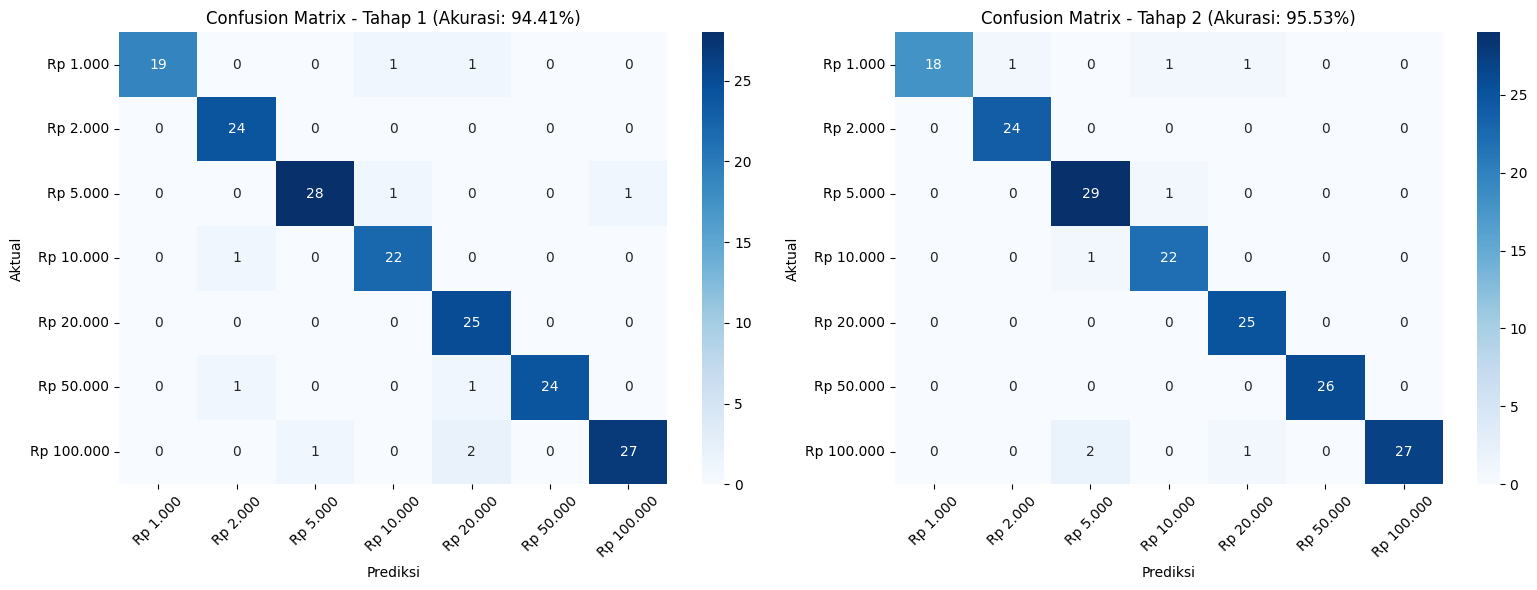

Dua Confusion Matrix (Tahap 1 vs Tahap 2) berhasil ditampilkan dan disimpan ke: /kaggle/working/models/mobilenetv2_confusion_matrices.png


In [18]:
cm_t1 = confusion_matrix(y_true, pred_frozen)
cm_t2 = confusion_matrix(y_true, pred_ft)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix Tahap 1
sns.heatmap(cm_t1, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=target_names, yticklabels=target_names)
axes[0].set_title(f'Confusion Matrix - Tahap 1 (Akurasi: {acc_t1*100:.2f}%)')
axes[0].set_ylabel('Aktual')
axes[0].set_xlabel('Prediksi')
axes[0].tick_params(axis='x', rotation=45)

# Confusion Matrix Tahap 2
sns.heatmap(cm_t2, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=target_names, yticklabels=target_names)
axes[1].set_title(f'Confusion Matrix - Tahap 2 (Akurasi: {acc_t2*100:.2f}%)')
axes[1].set_ylabel('Aktual')
axes[1].set_xlabel('Prediksi')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
cm_path = os.path.join(MODEL_DIR, 'mobilenetv2_confusion_matrices.png')
plt.savefig(cm_path, dpi=130)
plt.show()
print('Dua Confusion Matrix (Tahap 1 vs Tahap 2) berhasil ditampilkan dan disimpan ke:', cm_path)


## 10. Simpan Model Final


In [19]:
# 1. Simpan model final hasil fine-tuning
model_ft.save(FINAL_MODEL_PATH)
print('Model final berhasil disimpan ke:', FINAL_MODEL_PATH)

# 2. Tampilkan ringkasan seluruh file model dan artefak yang tersimpan
print('\n=== Ringkasan File Model dan Artefak yang Disimpan ===')
saved_items = [
    {
        'Nama File': 'mobilenetv2_frozen.keras',
        'Ukuran': f"{os.path.getsize(MODEL_SAVE_PATH)/(1024*1024):.2f} MB" if os.path.exists(MODEL_SAVE_PATH) else '-',
        'Tahapan': 'Tahap 1 (Backbone Frozen)',
        'Deskripsi / Kegunaan': 'Checkpoint terbaik saat hanya classifier head yang dilatih'
    },
    {
        'Nama File': 'mobilenetv2_finetuned.keras',
        'Ukuran': f"{os.path.getsize(FINETUNE_SAVE_PATH)/(1024*1024):.2f} MB" if os.path.exists(FINETUNE_SAVE_PATH) else '-',
        'Tahapan': 'Tahap 2 (Fine-Tuning)',
        'Deskripsi / Kegunaan': 'Checkpoint terbaik selama proses fine-tuning'
    },
    {
        'Nama File': 'mobilenetv2_rupiah.keras',
        'Ukuran': f"{os.path.getsize(FINAL_MODEL_PATH)/(1024*1024):.2f} MB" if os.path.exists(FINAL_MODEL_PATH) else '-',
        'Tahapan': 'Model Final (Deployment)',
        'Deskripsi / Kegunaan': 'Model siap pakai untuk inferensi backend API dan aplikasi'
    },
    {
        'Nama File': 'mobilenetv2_training_curves.png',
        'Ukuran': f"{os.path.getsize(os.path.join(MODEL_DIR, 'mobilenetv2_training_curves.png'))/1024:.1f} KB" if os.path.exists(os.path.join(MODEL_DIR, 'mobilenetv2_training_curves.png')) else '-',
        'Tahapan': 'Visualisasi',
        'Deskripsi / Kegunaan': 'Grafik kurva akurasi dan loss Tahap 1 dan Tahap 2'
    },
    {
        'Nama File': 'mobilenetv2_confusion_matrices.png',
        'Ukuran': f"{os.path.getsize(os.path.join(MODEL_DIR, 'mobilenetv2_confusion_matrices.png'))/1024:.1f} KB" if os.path.exists(os.path.join(MODEL_DIR, 'mobilenetv2_confusion_matrices.png')) else '-',
        'Tahapan': 'Evaluasi',
        'Deskripsi / Kegunaan': 'Perbandingan Confusion Matrix Tahap 1 vs Tahap 2'
    }
]

df_saved = pd.DataFrame(saved_items)
display(df_saved)


Model final berhasil disimpan ke: /kaggle/working/models/mobilenetv2_rupiah.keras

=== Ringkasan File Model dan Artefak yang Disimpan ===


,Nama File,Ukuran,Tahapan,Deskripsi / Kegunaan
0,mobilenetv2_frozen.keras,11.06 MB,Tahap 1 (Backbone Frozen),Checkpoint terbaik saat hanya classifier head ...
1,mobilenetv2_finetuned.keras,22.73 MB,Tahap 2 (Fine-Tuning),Checkpoint terbaik selama proses fine-tuning
2,mobilenetv2_rupiah.keras,22.72 MB,Model Final (Deployment),Model siap pakai untuk inferensi backend API d...
3,mobilenetv2_training_curves.png,87.9 KB,Visualisasi,Grafik kurva akurasi dan loss Tahap 1 dan Tahap 2
4,mobilenetv2_confusion_matrices.png,78.3 KB,Evaluasi,Perbandingan Confusion Matrix Tahap 1 vs Tahap 2
